Dataset loaded successfully!
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450

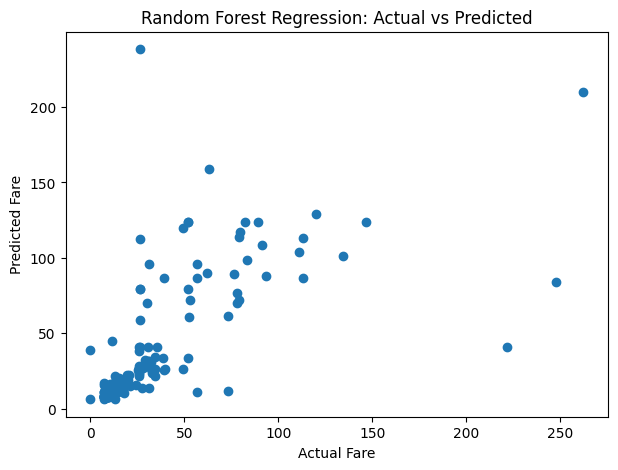


NEW PASSENGER PREDICTION
-------------------------
Passenger Details:
   Pclass     Sex  Age  SibSp  Parch
0       1  female   28      0      0
Predicted Fare: 104.14


In [ ]:

# RANDOM FOREST REGRESSION - TITANIC DATASET

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Load dataset
df = pd.read_csv('/content/Titanic-Dataset.csv')

print("Dataset loaded successfully!")
print(df.head())

# 3. Select input features and target
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch']
target = 'Fare'

# Check required columns
required_columns = features + [target]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns in dataset: {missing_columns}")

X = df[features].copy()
y = pd.to_numeric(df[target], errors='coerce')

# Remove rows where target Fare is missing
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

# 4. Separate numerical and categorical columns
numerical_features = ['Age', 'SibSp', 'Parch']
categorical_features = ['Pclass', 'Sex']

# 5. Handle missing values and encode categories
numerical_transformer = SimpleImputer(strategy='median')

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

# 6. Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7. Create Random Forest Regression model
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        criterion='squared_error',
        max_features=1.0,
        bootstrap=True,
        random_state=42
    ))
])

# 8. Train the model
model.fit(X_train, y_train)

print("\nModel trained successfully!")

# 9. Predict Fare
y_pred = model.predict(X_test)

# 10. Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("-------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# 11. Compare actual and predicted values
comparison = pd.DataFrame({
    'Actual Fare': y_test.values,
    'Predicted Fare': y_pred
})

print("\nACTUAL VS PREDICTED FARE")
print(comparison.head(10).round(2))

# 12. Plot actual vs predicted values
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Random Forest Regression: Actual vs Predicted")
plt.show()

# 13. Predict Fare for a new passenger
new_passenger = pd.DataFrame({
    'Pclass': [1],
    'Sex': ['female'],
    'Age': [28],
    'SibSp': [0],
    'Parch': [0]
})

predicted_fare = model.predict(new_passenger)

print("\nNEW PASSENGER PREDICTION")
print("-------------------------")
print("Passenger Details:")
print(new_passenger)
print("Predicted Fare:", round(predicted_fare[0], 2))
